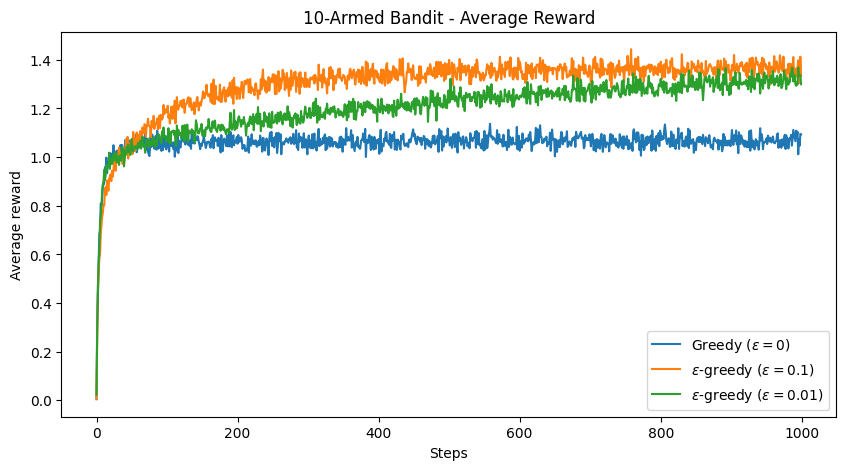

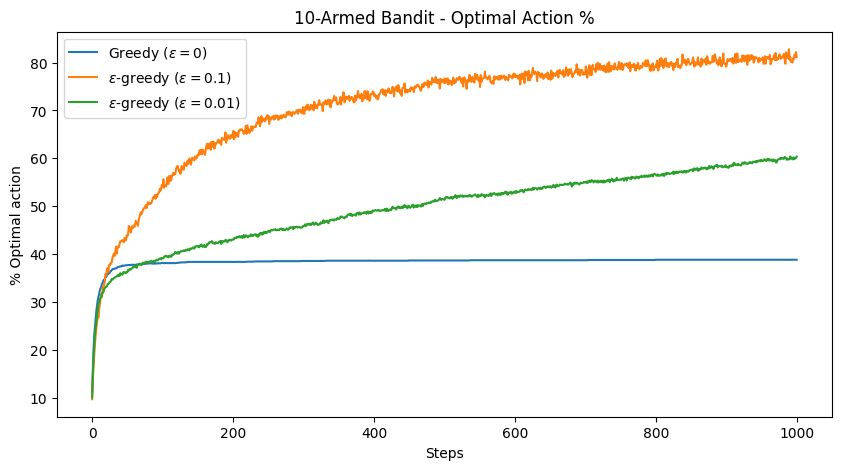

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def simulate(num_runs=2000, num_steps=1000, epsilon=0.0):
    """Simulates a 10-armed testbed using sample-average updates."""
    rewards = np.zeros((num_runs, num_steps))
    optimal_actions = np.zeros((num_runs, num_steps))

    for run in range(num_runs):
        # True action values q*(a) sampled from a standard normal distribution
        q_true = np.random.randn(10)
        best_action = np.argmax(q_true)

        # Estimated values Q(a) and action counts N(a)
        q_est = np.zeros(10)
        action_counts = np.zeros(10)

        for step in range(num_steps):
            # Epsilon-greedy action selection
            if np.random.rand() < epsilon:
                # FIXED: Used np.random.choice instead of np.choice
                action = np.random.choice(10)
            else:
                # Break ties randomly for true greedy choice
                action = np.random.choice(np.flatnonzero(q_est == q_est.max()))

            # Save if this was the optimal action
            if action == best_action:
                optimal_actions[run, step] = 1

            # Reward R_t ~ N(q*(a), 1)
            reward = q_true[action] + np.random.randn()
            rewards[run, step] = reward

            # Sample-average update: Q(a) = Q(a) + (1 / N(a)) * (R - Q(a))
            action_counts[action] += 1
            q_est[action] += (reward - q_est[action]) / action_counts[action]

    # Return average reward and optimal action percentage per step
    return np.mean(rewards, axis=0), np.mean(optimal_actions, axis=0) * 100

# Simulation configurations
steps = 1000
runs = 2000

# Run experiments
r_greedy, opt_greedy = simulate(num_runs=runs, num_steps=steps, epsilon=0.0)
r_eps01, opt_eps01 = simulate(num_runs=runs, num_steps=steps, epsilon=0.1)
r_eps001, opt_eps001 = simulate(num_runs=runs, num_steps=steps, epsilon=0.01)

# Plot Average Reward
plt.figure(figsize=(10, 5))
# FIXED: Prefixed string labels with 'r' to prevent SyntaxWarning
plt.plot(r_greedy, label=r'Greedy ($\epsilon = 0$)')
plt.plot(r_eps01, label=r'$\epsilon$-greedy ($\epsilon = 0.1$)')
plt.plot(r_eps001, label=r'$\epsilon$-greedy ($\epsilon = 0.01$)')
plt.xlabel('Steps')
plt.ylabel('Average reward')
plt.legend()
plt.title('10-Armed Bandit - Average Reward')
plt.show()

# Plot % Optimal Action
plt.figure(figsize=(10, 5))
plt.plot(opt_greedy, label=r'Greedy ($\epsilon = 0$)')
plt.plot(opt_eps01, label=r'$\epsilon$-greedy ($\epsilon = 0.1$)')
plt.plot(opt_eps001, label=r'$\epsilon$-greedy ($\epsilon = 0.01$)')
plt.xlabel('Steps')
plt.ylabel('% Optimal action')
plt.legend()
plt.title('10-Armed Bandit - Optimal Action %')
plt.show()